[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vvvvvivekkk/AI-Engineer/blob/main/09-rag/notebooks/01-loading-and-chunking.ipynb)

# 09.01 — Loading documents and chunking strategies

**RAG** (Retrieval-Augmented Generation) = *find the relevant passages in your documents, then give them to the model with the question.* Before we can find passages, we need to **load** documents and cut them into **chunks** (small passages).

**What you will learn**
- How to load Markdown files with their **metadata** (facts about each file such as its name and title).
- Three chunking strategies: **fixed-size**, **fixed-size with overlap**, and **recursive by headings**.
- How to *see* where each strategy cuts, and compare chunk counts and sizes.

**Our data:** 15 short policy documents for **Brightleaf Outdoor Gear**, a made-up outdoor shop (returns, shipping, warranty, payments ...). Runs offline in under a minute.

## Find the data (works locally and in Colab)

The documents live in the module's `data/docs/` folder. Locally the notebook finds them next door. In Colab the cell downloads them (and the helper code) from the course's GitHub repository.

In [1]:
import sys, urllib.request
from pathlib import Path
RAW = "https://raw.githubusercontent.com/vvvvvivekkk/AI-Engineer/main/09-rag/"
DOC_NAMES = ['01-returns-policy.md', '02-exchanges.md', '03-shipping-and-delivery.md', '04-warranty.md', '05-repairs-service.md', '06-payments-and-billing.md', '07-price-match.md', '08-gold-membership.md', '09-gear-rental.md', '10-account-and-privacy.md', '11-sustainability.md', '12-stores-and-hours.md', '13-customer-support.md', '14-gift-cards.md', '15-safety-recalls.md']
EXTRA = ["data/eval_questions.json", "code/rag_pipeline.py"]

BASE = next((p for p in [Path(".."), Path("09-rag"), Path(".")] if (p / "data" / "docs").exists()), None)
if BASE is None:                                   # not found locally -> download (Colab)
    BASE = Path("09-rag")
    for rel in [f"data/docs/{n}" for n in DOC_NAMES] + EXTRA:
        dest = BASE / rel
        dest.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(RAW + rel, dest)
DOCS_DIR = BASE / "data" / "docs"
sys.path.insert(0, str(BASE / "code"))             # so "import rag_pipeline" works
print("documents folder:", DOCS_DIR.resolve(), "|", len(list(DOCS_DIR.glob("*.md"))), "files")

documents folder: /home/claude/AI-Engineer/09-rag/data/docs | 15 files


## 1. Load the documents

Each file becomes a small record: its id (file name), its title (the first `# ` heading) and its full text. Keeping the id matters: later it becomes the **citation** that tells users where an answer came from.

In [2]:
from dataclasses import dataclass

@dataclass
class Document:
    doc_id: str
    title: str
    text: str

def load_documents(folder):
    docs = []
    for path in sorted(Path(folder).glob("*.md")):
        text = path.read_text(encoding="utf-8")
        title = next((l[2:].strip() for l in text.splitlines() if l.startswith("# ")), path.stem)
        docs.append(Document(path.name, title, text))
    return docs

docs = load_documents(DOCS_DIR)
for d in docs:
    print(f"{d.doc_id:<30} {len(d.text.split()):>4} words | {d.title}")

01-returns-policy.md            227 words | Returns Policy
02-exchanges.md                 166 words | Exchanges
03-shipping-and-delivery.md     210 words | Shipping and Delivery
04-warranty.md                  172 words | Warranty
05-repairs-service.md           153 words | Repair Service
06-payments-and-billing.md      158 words | Payments and Billing
07-price-match.md               132 words | Price Match Promise
08-gold-membership.md           142 words | Brightleaf Gold Membership
09-gear-rental.md               161 words | Gear Rental
10-account-and-privacy.md       180 words | Account and Privacy
11-sustainability.md            135 words | Sustainability Commitments
12-stores-and-hours.md          104 words | Stores and Opening Hours
13-customer-support.md          118 words | Customer Support
14-gift-cards.md                119 words | Gift Cards
15-safety-recalls.md            144 words | Product Safety and Recalls


Let's read one document in full, so we know what we are cutting up. Notice the `##` section headings — they are the document's natural boundaries.

In [3]:
print(docs[3].text)

# Warranty

Brightleaf products are built to last. Every product sold under the Brightleaf brand comes with a warranty against manufacturing defects.

## Warranty periods

- Tents, backpacks and sleeping bags: **5 years**
- Jackets, trousers and other clothing: **2 years**
- Footwear: **1 year**
- Electronics such as headlamps and GPS units: **2 years**

Products from other brands carry the manufacturer's warranty, which we help you claim.

## What the warranty covers

The warranty covers faults in materials and workmanship, such as broken seams, failed zips that were not misused, and delamination of waterproof membranes.

## What the warranty does not cover

Normal wear and tear, accidental damage, damage from improper washing, and modifications made by the customer are not covered.

## Making a warranty claim

Send a claim through the **Warranty** form with your order number, photos of the fault and a short description. Our repair team answers within 5 business days. We repair the pr

## 2. Strategy A — fixed-size chunks

Cut every *N* words, no matter what. Like cutting a sausage into equal slices: easy and predictable, but the knife lands wherever it lands — sometimes in the middle of a sentence or a list.

In [4]:
@dataclass
class Chunk:
    chunk_id: str
    doc_id: str
    section: str
    text: str

def chunk_fixed(doc, size=80, overlap=0):
    words = doc.text.split()
    step = max(1, size - overlap)              # how far the window moves each time
    chunks = []
    for i, start in enumerate(range(0, len(words), step)):
        piece = words[start:start + size]
        chunks.append(Chunk(f"{doc.doc_id}#{i}", doc.doc_id, doc.title, " ".join(piece)))
        if start + size >= len(words):
            break
    return chunks

fixed = chunk_fixed(docs[3], size=80)
for c in fixed:
    print(c.chunk_id, "|", c.text[:90], "...", c.text[-50:], "\n")

04-warranty.md#0 | # Warranty Brightleaf products are built to last. Every product sold under the Brightleaf  ... covers The warranty covers faults in materials and 

04-warranty.md#1 | workmanship, such as broken seams, failed zips that were not misused, and delamination of  ...  business days. We repair the product if possible; 

04-warranty.md#2 | if not, we replace it or give store credit for its value. ...  we replace it or give store credit for its value. 



Look at where chunks start and end: mid-sentence, and the list of warranty periods may be split from its heading. A question like *"how long is the tent warranty?"* might match a chunk that contains "5 years" but not the word "Tents".

## 3. Strategy B — fixed-size with overlap

Each chunk repeats the last 20 words of the previous one. A fact that straddles a boundary now appears whole in at least one chunk. The price: more chunks and some duplicated text.

In [5]:
overlap = chunk_fixed(docs[3], size=80, overlap=20)
print(len(fixed), "chunks without overlap ->", len(overlap), "chunks with 20-word overlap\n")
a, b = overlap[0].text.split(), overlap[1].text.split()
print("end of chunk 0  :", " ".join(a[-20:]))
print("start of chunk 1:", " ".join(b[:20]))

3 chunks without overlap -> 3 chunks with 20-word overlap

end of chunk 0  : the manufacturer's warranty, which we help you claim. ## What the warranty covers The warranty covers faults in materials and
start of chunk 1: the manufacturer's warranty, which we help you claim. ## What the warranty covers The warranty covers faults in materials and


The end of chunk 0 and the start of chunk 1 are the same 20 words — that is the overlap.

## 4. Strategy C — recursive chunking by headings

Respect the document's structure, like cutting a cake along the lines of its slices:
1. Split at `##` headings (one section = one idea).
2. If a section is still too long, split it at blank lines (paragraphs).
3. If a paragraph is still too long, fall back to fixed-size pieces.

Each chunk also gets a **prefix** with the document title and section heading (`Warranty > Warranty periods`), so it makes sense on its own and matches questions that mention its topic.

In [6]:
def chunk_by_headings(doc, max_words=120):
    sections, heading, lines = [], doc.title, []
    for line in doc.text.splitlines():
        if line.startswith("## "):
            if lines:
                sections.append((heading, "\n".join(lines).strip()))
            heading, lines = line[3:].strip(), []
        elif not line.startswith("# "):
            lines.append(line)
    if lines:
        sections.append((heading, "\n".join(lines).strip()))
    chunks = []
    for heading, body in sections:
        if not body:
            continue
        pieces = [body] if len(body.split()) <= max_words else [p for p in body.split("\n\n") if p.strip()]
        for piece in pieces:
            words = piece.split()
            subs = [piece] if len(words) <= max_words else [" ".join(words[i:i + max_words]) for i in range(0, len(words), max_words)]
            for s in subs:
                chunks.append(Chunk(f"{doc.doc_id}#{len(chunks)}", doc.doc_id, heading, f"{doc.title} > {heading}\n{s.strip()}"))
    return chunks

for c in chunk_by_headings(docs[3]):
    print(f"--- {c.chunk_id}  ({len(c.text.split())} words)\n{c.text}\n")

--- 04-warranty.md#0  (23 words)
Warranty > Warranty
Brightleaf products are built to last. Every product sold under the Brightleaf brand comes with a warranty against manufacturing defects.

--- 04-warranty.md#1  (47 words)
Warranty > Warranty periods
- Tents, backpacks and sleeping bags: **5 years**
- Jackets, trousers and other clothing: **2 years**
- Footwear: **1 year**
- Electronics such as headlamps and GPS units: **2 years**

Products from other brands carry the manufacturer's warranty, which we help you claim.

--- 04-warranty.md#2  (29 words)
Warranty > What the warranty covers
The warranty covers faults in materials and workmanship, such as broken seams, failed zips that were not misused, and delamination of waterproof membranes.

--- 04-warranty.md#3  (27 words)
Warranty > What the warranty does not cover
Normal wear and tear, accidental damage, damage from improper washing, and modifications made by the customer are not covered.

--- 04-warranty.md#4  (51 words)
Warranty >

Every chunk is now one complete idea with a label. This usually retrieves better — but always check with real questions (notebook 03 does exactly that).

## 5. See the cuts

A picture makes the difference obvious. Each row is one strategy applied to the warranty document. Each coloured block is a chunk (position measured in words). Dashed lines mark where the `##` headings are. Fixed-size chunks ignore the headings; heading chunks line up with them; overlapping chunks are drawn as staggered bars.

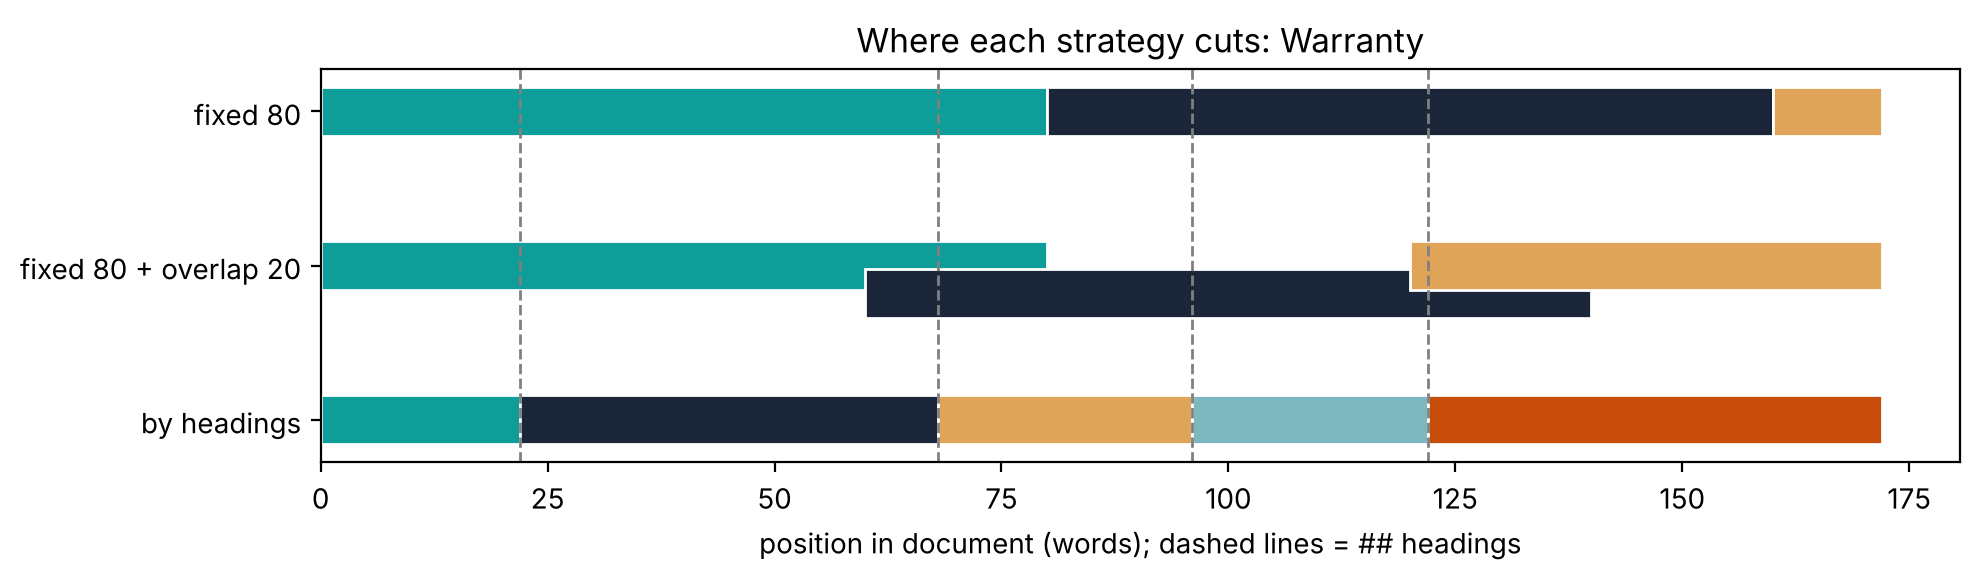

In [7]:
import matplotlib.pyplot as plt

def heading_positions(doc):
    pos, count = [], 0
    for line in doc.text.splitlines():
        if line.startswith("## "):
            pos.append(count)
        count += len(line.split())
    return pos

def spans_fixed(doc, size, overlap):
    n, step = len(doc.text.split()), size - overlap
    return [(s, min(s + size, n)) for s in range(0, n, step) if s < n and (s == 0 or s + overlap < n)]

def spans_headings(doc):
    words = doc.text.split(); n = len(words)
    bounds = heading_positions(doc) + [n]
    return [(a, b) for a, b in zip([0] + bounds[:-1], bounds) if b > a]

def plot_cuts(doc, ax_title=None):
    rows = [("fixed 80", spans_fixed(doc, 80, 0)), ("fixed 80 + overlap 20", spans_fixed(doc, 80, 20)),
            ("by headings", spans_headings(doc))]
    colors = ["#0F9D9A", "#1B263B", "#E0A458", "#7FB7BE", "#C84C09", "#5A6370"]
    fig, ax = plt.subplots(figsize=(10, 3))
    for r, (name, spans) in enumerate(rows):
        for j, (a, b) in enumerate(spans):
            dy = (j % 2) * 0.18 if "overlap" in name else 0
            ax.barh(r + dy, b - a, left=a, height=0.32, color=colors[j % len(colors)], edgecolor="white")
    for h in heading_positions(doc):
        ax.axvline(h, color="grey", ls="--", lw=1)
    ax.set_yticks(range(len(rows)), [n for n, _ in rows]); ax.invert_yaxis()
    ax.set_xlabel("position in document (words); dashed lines = ## headings")
    ax.set_title(ax_title or f"Where each strategy cuts: {doc.title}")
    plt.tight_layout(); plt.show()

plot_cuts(docs[3])

## 6. Compare the strategies across all 15 documents

Count chunks and look at their sizes. Many tiny chunks lack context; a few huge chunks give blurry search results.

In [8]:
import pandas as pd
strategies = {"fixed-80": lambda d: chunk_fixed(d, 80, 0),
              "fixed-80-overlap-20": lambda d: chunk_fixed(d, 80, 20),
              "headings": lambda d: chunk_by_headings(d, 120)}
all_chunks = {name: [c for d in docs for c in fn(d)] for name, fn in strategies.items()}
stats = pd.DataFrame([{"strategy": n, "chunks": len(cs),
                       "mean words": round(sum(len(c.text.split()) for c in cs) / len(cs), 1),
                       "min words": min(len(c.text.split()) for c in cs),
                       "max words": max(len(c.text.split()) for c in cs),
                       "total words stored": sum(len(c.text.split()) for c in cs)} for n, cs in all_chunks.items()])
stats

,strategy,chunks,mean words,min words,max words,total words stored
0,fixed-80,36,64.5,1,80,2321
1,fixed-80-overlap-20,42,68.1,22,80,2861
2,headings,73,33.9,13,66,2474


Notice: overlap stores more words in total (duplication); heading chunks vary in size because sections vary. A histogram shows the spread.

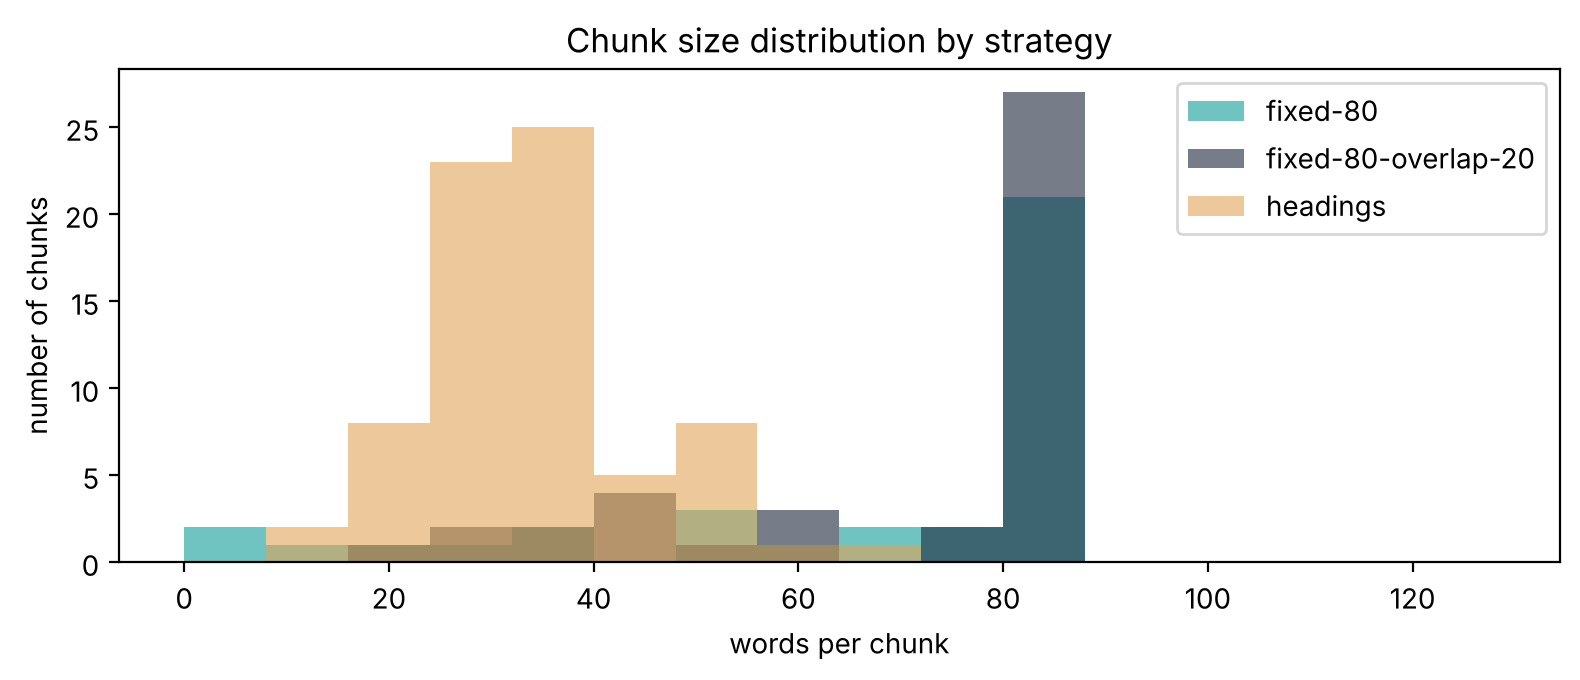

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.5))
for (name, cs), color in zip(all_chunks.items(), ["#0F9D9A", "#1B263B", "#E0A458"]):
    ax.hist([len(c.text.split()) for c in cs], bins=range(0, 130, 8), alpha=0.6, label=name, color=color)
ax.set_xlabel("words per chunk"); ax.set_ylabel("number of chunks"); ax.legend()
ax.set_title("Chunk size distribution by strategy"); plt.tight_layout(); plt.show()

## 7. The same code, packaged

These functions live in `code/rag_pipeline.py` so the next notebooks can reuse them. Let's check the packaged version gives the same counts.

In [10]:
import rag_pipeline as rp
for name in rp.CHUNKERS:
    print(f"{name:<22}", len(rp.chunk_all(rp.load_documents(DOCS_DIR), name)), "chunks")

fixed-80               36 chunks
fixed-80-overlap-20    42 chunks
headings               73 chunks


## Recap
- **Load** documents with metadata (id, title) — the id becomes the citation.
- **Fixed-size** chunking is simple but cuts blindly; **overlap** protects facts on boundaries at the cost of duplication; **heading-based (recursive)** chunking keeps one idea per chunk and adds a helpful title prefix.
- There is no universal best chunk size: **measure** with your own questions (notebook 03).

**Try it:** change `size=80` to `size=40` and `size=200`. How do the chunk counts and the cut picture change? Which would you expect to retrieve better, and why?